# Examining Sub-Research Research Question 3: Word Count

The third sub-research question is as follows: **'Are there differences in content between homosexual and heterosexual fan fiction on Archive of Our Own, regarding variables such as the language, date published, or word count?**

In [1]:
# Import package
import polars as pl
import pyarrow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_metadata = pl.read_ndjson("./data/combined_metadata.jsonl") # Create the df_metadata DataFrame
df_metadata = df_metadata.unnest('metadata') # Turn the metadata column into 18 separate columns

fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]

# Select the target fandom and relationship categories
df_metadata = df_metadata.filter(
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]) |
    (pl.col("Fandom") == fandoms[2])) &
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M") |
    (pl.col("Category") == "F/M"))
)

df_metadata.head()

id,title,Additional Tags,Archive Warning,Category,Characters,Fandoms,Language,Rating,Relationship,author,chapters,completed,published,words,Fandom,Character,Collections,Series,Relationships
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""10012010""","""Just One Training""","""Explicit Sexual Content, Oral …","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Explicit""","""Sara Lance/Leonard Snart""","""by capnwho""","""1/1""","""""","""2017-02-28""","""1,470""","""DC's Legends of Tomorrow (TV)""",null,null,"""Just One Fixation""",null
"""10013705""","""Five Months More""","""Established Relationship, surp…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart""",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-02-28""","""505""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"
"""10018964""","""It Ends with a Kiss""","""Alpha/Beta/Omega Dynamics, Min…","""No Archive Warnings Apply""","""M/M""","""Leonard Snart, Ray Palmer, Mic…",null,"""English""","""Teen And Up Audiences""","""Ray Palmer/Leonard Snart""","""by Constantsnow""","""1/1""","""""","""2017-02-28""","""3,008""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10030784""","""Bet""",null,"""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""General Audiences""","""Sara Lance/Leonard Snart""","""by orphan_account""","""1/1""","""""","""2017-03-01""","""1,273""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10033958""","""For the Both of Us""","""Captain Canary, ficcingcaptain…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-03-01""","""1,067""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"


In [3]:
df_metadata = df_metadata.with_columns(pl.col("words").str.replace_all(",", "").cast(pl.Int64, strict=False)) # change str to int

In [ ]:
# Calculate the word_count frequencies
ff_mm_word_count_amt = df_metadata.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")
).select(pl.col("words").value_counts()).unnest("words").sort("count", descending=True) # Filtered by F/F + M/M
fm_word_count_amt = df_metadata.filter(
    (pl.col("Category") == "F/M")
).select(pl.col("words").value_counts()).unnest("words").sort("count", descending=True) # Filtered by F/M

In [5]:
# Create lists
ff_mm_word_count_list = ff_mm_word_count_amt.to_series().to_list()
fm_word_count_list = fm_word_count_amt.to_series().to_list()

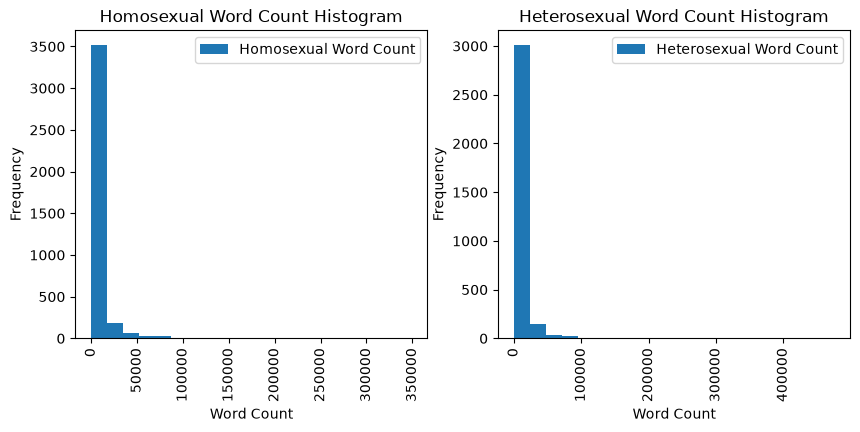

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Filtered by F/F + M/M
ax[0].hist(ff_mm_word_count_amt['words'], bins=20)

ax[0].set_title("Homosexual Word Count Histogram")
ax[0].set_xlabel("Word Count")
ax[0].set_ylabel("Frequency")
ax[0].tick_params(axis="x", labelrotation=90)

ax[0].legend(['Homosexual Word Count'])

# Filtered by F/M
ax[1].hist(fm_word_count_amt['words'], bins=20)

ax[1].set_title("Heterosexual Word Count Histogram")
ax[1].set_xlabel("Word Count")
ax[1].set_ylabel("Frequency")
ax[1].tick_params(axis="x", labelrotation=90)

ax[1].legend(['Heterosexual Word Count'])
plt.show()

## 1. Ratings

### 1.1 Creating the Ratings Datasets

In [39]:
ratings = ["Not Rated", "General Audiences", "Teen And Up Audiences", "Mature", "Explicit"]

# Filtered by F/F + M/M
ff_mm_wc_ratings = pl.DataFrame()
for rating in ratings:
    ff_mm_wc_rating = df_metadata.filter(
        ((pl.col("Category") == "F/F") |
        (pl.col("Category") == "M/M")) &
        (pl.col("Rating") == rating)
    ).select(pl.col("words").value_counts()).unnest("words").with_columns(new_column = pl.lit(rating)).rename({"new_column": "Rating"})
    ff_mm_wc_ratings = pl.concat([ff_mm_wc_ratings, ff_mm_wc_rating])

# Filtered by F/F + M/M
fm_wc_ratings = pl.DataFrame()
for rating in ratings:
    fm_wc_rating = df_metadata.filter(
        (pl.col("Category") == "F/M") &
        (pl.col("Rating") == rating)
    ).select(pl.col("words").value_counts()).unnest("words").with_columns(new_column = pl.lit(rating)).rename({"new_column": "Rating"})
    fm_wc_ratings = pl.concat([fm_wc_ratings, fm_wc_rating])

print("Homosexual Ratings Amount per word count:")
ff_mm_wc_ratings.show()
print("Heterosexual Ratings Amount per word count:")
fm_wc_ratings.show()

Homosexual Ratings Amount per word count:


words,count,Rating
i64,u32,str
10759,1,"""Not Rated"""
3631,1,"""Not Rated"""
485,1,"""Not Rated"""
9854,1,"""Not Rated"""
729,1,"""Not Rated"""


Heterosexual Ratings Amount per word count:


words,count,Rating
i64,u32,str
273,1,"""Not Rated"""
2103,1,"""Not Rated"""
554,1,"""Not Rated"""
2300,1,"""Not Rated"""
1596,1,"""Not Rated"""


### 1.2 Visualizing the Ratings Datasets

C:\Users\camer\AppData\Local\Temp\ipykernel_15812\3190125397.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[0].set_xticklabels(ratings, rotation=90)
C:\Users\camer\AppData\Local\Temp\ipykernel_15812\3190125397.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[1].set_xticklabels(ratings, rotation=90)


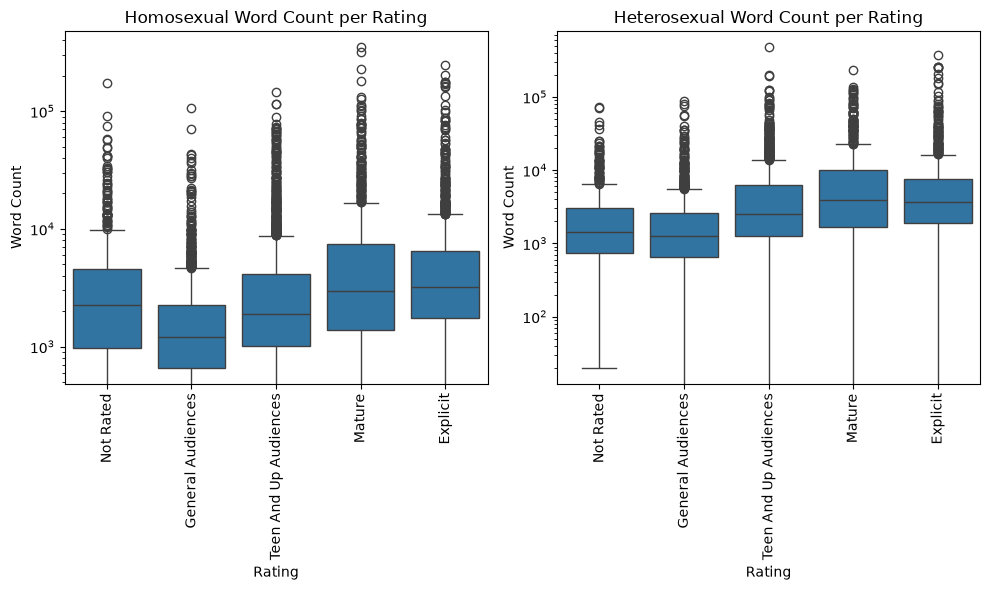

In [46]:
fig, ax = plt.subplots(1, 2, figsize=(10, 6)) # Set figure size

# Filtered by F/F + M/M
ff_mm_ratings_boxplot = ff_mm_wc_ratings.to_pandas() # Convert Polars to pandas
ff_mm_ratings_boxplot = ff_mm_ratings_boxplot.loc[ff_mm_ratings_boxplot.index.repeat(ff_mm_ratings_boxplot["count"])].reset_index(drop=True) # Repeat each row according to its frequency

# Create the box plots
ax[0] = sns.boxplot(
    data=ff_mm_ratings_boxplot,
    x="Rating",
    y="words",
    ax=ax[0]
)

ax[0].set_xlabel("Rating")
ax[0].set_ylabel("Word Count")
ax[0].set_title("Homosexual Word Count per Rating")

# Filtered by F/M
fm_ratings_boxplot = fm_wc_ratings.to_pandas() # Convert Polars to pandas
fm_ratings_boxplot = fm_ratings_boxplot.loc[fm_ratings_boxplot.index.repeat(fm_ratings_boxplot["count"])].reset_index(drop=True) # Repeat each row according to its frequency

# Create the box plots
sns.boxplot(
    data=fm_ratings_boxplot,
    x="Rating",
    y="words",
    ax=ax[1]
)

ax[1].set_xlabel("Rating")
ax[1].set_ylabel("Word Count")
ax[1].set_title("Heterosexual Word Count per Rating")

ax[0].set_yscale("log")
ax[1].set_yscale("log")

ax[0].set_xticklabels(ratings, rotation=90)
ax[1].set_xticklabels(ratings, rotation=90)

plt.tight_layout()
plt.show()

## 2. Archive Warnings

### 2.1 Creating the Archive Warnings Datasets

In [42]:
aws = ['Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con']

# Filtered by F/F + M/M
ff_mm_wc_aws = pl.DataFrame()
for aw in aws:
    ff_mm_wc_aw = df_metadata.filter(
        ((pl.col("Category") == "F/F") |
        (pl.col("Category") == "M/M")) &
        (pl.col("Archive Warning") == aw)
    ).select(pl.col("words").value_counts()).unnest("words").with_columns(new_column = pl.lit(aw)).rename({"new_column": "Archive Warning"})
    ff_mm_wc_aws = pl.concat([ff_mm_wc_aws, ff_mm_wc_aw])

# Filtered by F/F + M/M
fm_wc_aws = pl.DataFrame()
for aw in aws:
    fm_wc_aw = df_metadata.filter(
        (pl.col("Category") == "F/M") &
        (pl.col("Archive Warning") == aw)
    ).select(pl.col("words").value_counts()).unnest("words").with_columns(new_column = pl.lit(aw)).rename({"new_column": "Archive Warning"})
    fm_wc_aws = pl.concat([fm_wc_aws, fm_wc_aw])

print("Homosexual Archive Warnings Amount per word count:")
ff_mm_wc_aws.show()
print("Heterosexual Archive Warnings Amount per word count:")
fm_wc_aws.show()

Homosexual Archive Warnings Amount per word count:


words,count,Archive Warning
i64,u32,str
1435,1,"""Creator Chose Not To Use Archi…"
7152,1,"""Creator Chose Not To Use Archi…"
7031,1,"""Creator Chose Not To Use Archi…"
1445,1,"""Creator Chose Not To Use Archi…"
1879,2,"""Creator Chose Not To Use Archi…"


Heterosexual Archive Warnings Amount per word count:


words,count,Archive Warning
i64,u32,str
4421,2,"""Creator Chose Not To Use Archi…"
11991,1,"""Creator Chose Not To Use Archi…"
2458,1,"""Creator Chose Not To Use Archi…"
2778,1,"""Creator Chose Not To Use Archi…"
511,2,"""Creator Chose Not To Use Archi…"


### 2.2 Visualizing the Archive Warnings Datasets

C:\Users\camer\AppData\Local\Temp\ipykernel_15812\3134821415.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[0].set_xticklabels(aws, rotation=90)
C:\Users\camer\AppData\Local\Temp\ipykernel_15812\3134821415.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[1].set_xticklabels(aws, rotation=90)


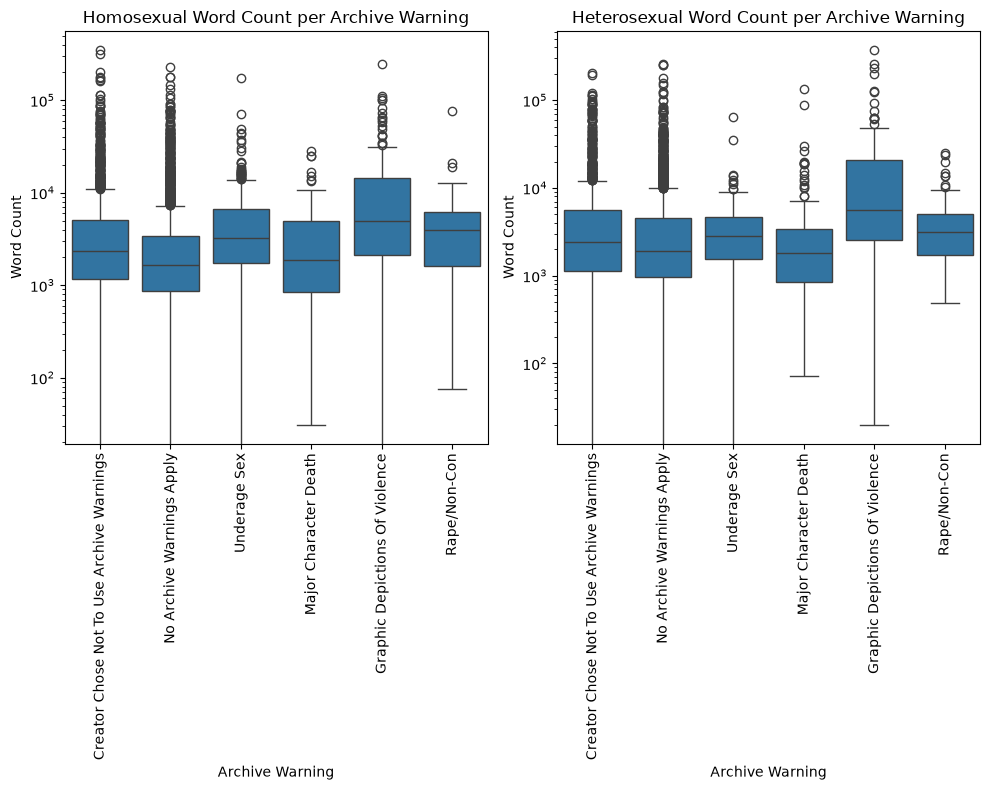

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(10, 8)) # Set figure size

# Filtered by F/F + M/M
ff_mm_aws_boxplot = ff_mm_wc_aws.to_pandas() # Convert Polars to pandas
ff_mm_aws_boxplot = ff_mm_aws_boxplot.loc[ff_mm_aws_boxplot.index.repeat(ff_mm_aws_boxplot["count"])].reset_index(drop=True) # Repeat each row according to its frequency

# Create the box plots
ax[0] = sns.boxplot(
    data=ff_mm_aws_boxplot,
    x="Archive Warning",
    y="words",
    ax=ax[0]
)

ax[0].set_xlabel("Archive Warning")
ax[0].set_ylabel("Word Count")
ax[0].set_title("Homosexual Word Count per Archive Warning")

# Filtered by F/M
fm_aws_boxplot = fm_wc_aws.to_pandas() # Convert Polars to pandas
fm_aws_boxplot = fm_aws_boxplot.loc[fm_aws_boxplot.index.repeat(fm_aws_boxplot["count"])].reset_index(drop=True) # Repeat each row according to its frequency

# Create the box plots
sns.boxplot(
    data=fm_aws_boxplot,
    x="Archive Warning",
    y="words",
    ax=ax[1]
)

ax[1].set_xlabel("Archive Warning")
ax[1].set_ylabel("Word Count")
ax[1].set_title("Heterosexual Word Count per Archive Warning")

ax[0].set_yscale("log")
ax[1].set_yscale("log")

ax[0].set_xticklabels(aws, rotation=90)
ax[1].set_xticklabels(aws, rotation=90)

plt.tight_layout()
plt.show()